# Catching Overworked Robot Joints with Linear Regression

**Course:** CSCN8010 · **Student:** Carlos Gutierrez (9118309)

The goal of this notebook is to find out when one of the eight joints of a robot is pulling
more current than it normally does, and to raise an **Alert** or an **Error** when that
happens for long enough to matter.

My plan:

1. Pull the old robot readings from my Neon database.
2. Fit one straight line per axis (time → current).
3. Look at the residuals (real value minus line) to decide what "too high" and "long enough" mean.
4. Make fake test data, send it through the database one batch at a time, and check that the rules catch the faults I plant in it.

**About units:** the assignment talks about kWh, but the file only has current in amps
(no voltage), so I can't get to energy. Everything below is in **amps above the regression line**,
and time is in seconds.

## 1. Setup

In [1]:
from pathlib import Path
import time
import uuid

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, Image
from psycopg.rows import dict_row
from sklearn.linear_model import LinearRegression

from src.data_collection.data_collection_agent import fetch_all, get_connection
from src.data_collection.streaming_simulator import StreamingSimulator

ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
OUT_DIR = ROOT / "results"
PLOT_DIR = OUT_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

AXES = [f"axis_{i}" for i in range(1, 9)]
SEED = 7
rng = np.random.default_rng(SEED)

pd.options.display.float_format = "{:,.3f}".format


def show(fig, name, height=900, width=1200):
    """Save the chart (html + png) and show the png in the notebook."""
    fig.update_layout(template="plotly_white", height=height, width=width,
                      margin=dict(l=60, r=30, t=80, b=50))
    fig.write_html(PLOT_DIR / f"{name}.html")
    png = fig.to_image(format="png", scale=1)
    (PLOT_DIR / f"{name}.png").write_bytes(png)
    display(Image(png))


assert (DATA_DIR / "RMBR4-2_export_test.csv").is_file(), "Start Jupyter from the project folder."
print("ready")

ready


## 2. Get the training data from Neon

The readings were loaded into the `robot_readings` table earlier. I query them from there
instead of reading the CSV.

In [2]:
raw = fetch_all()

hist = raw[["reading_time", *AXES]].copy()
hist["reading_time"] = pd.to_datetime(hist["reading_time"], utc=True)
hist = hist.sort_values("reading_time").reset_index(drop=True)

print("rows:", len(hist))
print("missing values:", int(hist.isna().sum().sum()))
print("duplicate timestamps:", int(hist["reading_time"].duplicated().sum()))
print("from", hist["reading_time"].min(), "to", hist["reading_time"].max())
hist.head()

rows: 39672
missing values: 0
duplicate timestamps: 0
from 2022-10-17 12:18:23.660000+00:00 to 2022-10-18 10:44:58.628000+00:00


,reading_time,axis_1,axis_2,axis_3,axis_4,axis_5,axis_6,axis_7,axis_8
0,2022-10-17 12:18:23.660000+00:00,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
1,2022-10-17 12:18:25.472000+00:00,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
2,2022-10-17 12:18:27.348000+00:00,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
3,2022-10-17 12:18:29.222000+00:00,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
4,2022-10-17 12:18:31.117000+00:00,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


Two things I want to know before fitting anything: how often readings arrive, and how many
rows are just the robot sitting still (all eight axes exactly 0).

In [3]:
T0 = hist["reading_time"].iloc[0]
hist["sec"] = (hist["reading_time"] - T0).dt.total_seconds()
hist["idle"] = (hist[AXES] == 0).all(axis=1)

step = hist["sec"].diff().dropna()
TYPICAL_STEP = step.median()
MAX_GAP = 3 * TYPICAL_STEP   # a jump bigger than this counts as a recording gap

print(f"typical time between readings: {TYPICAL_STEP:.2f} s")
print(f"recording gaps (> {MAX_GAP:.1f} s): {(step > MAX_GAP).sum()}")
print(f"idle rows (all axes = 0): {hist['idle'].mean():.1%}")

typical time between readings: 1.89 s
recording gaps (> 5.7 s): 701
idle rows (all axes = 0): 64.2%


About two thirds of the rows are idle zeros. If I include them, every line gets dragged down
and normal work would look "too high". So I **fit only on the rows where the robot is working**.
Idle rows are still checked later; they just can't produce a positive residual.

## 3. Train / test split and one regression per axis

I split by time, not randomly: the first 70% is for training and the last 30% is kept to see
whether the lines still make sense later in the day.

In [4]:
cut = int(len(hist) * 0.7)
train = hist.iloc[:cut]
test = hist.iloc[cut:]
train_work = train[~train["idle"]]
test_work = test[~test["idle"]]

print(f"train: {len(train):,} rows ({len(train_work):,} working)")
print(f"test:  {len(test):,} rows ({len(test_work):,} working)")

train: 27,770 rows (10,439 working)
test:  11,902 rows (3,746 working)


In [5]:
models = {}
rows = []
for ax in AXES:
    lr = LinearRegression().fit(train_work[["sec"]], train_work[ax])
    models[ax] = lr
    rows.append({
        "axis": ax,
        "intercept_A": lr.intercept_,
        "slope_A_per_hour": lr.coef_[0] * 3600,
        "R2_train": lr.score(train_work[["sec"]], train_work[ax]),
        "R2_test": lr.score(test_work[["sec"]], test_work[ax]),
    })

params = pd.DataFrame(rows).set_index("axis")
params.to_csv(OUT_DIR / "model_parameters.csv")
params

,intercept_A,slope_A_per_hour,R2_train,R2_test
axis,,,,
axis_1,2.006,0.006,0.000,-0.002
axis_2,10.003,0.007,0.000,-0.000
axis_3,7.839,-0.031,0.000,-0.004
axis_4,1.676,0.007,0.000,-0.001
axis_5,2.694,-0.003,0.000,-0.000
axis_6,1.683,-0.004,0.000,-0.003
axis_7,2.359,0.009,0.000,-0.001
axis_8,0.272,0.002,0.000,-0.001


The slopes are tiny and R² is about 0 on both sets. At first that looked like a failed model,
but I think it means something else: during a normal day the average load of each joint does not
trend up or down, so the best straight line is almost flat. That is what I would want from a
healthy baseline. A joint that is wearing out should start to climb above its line.

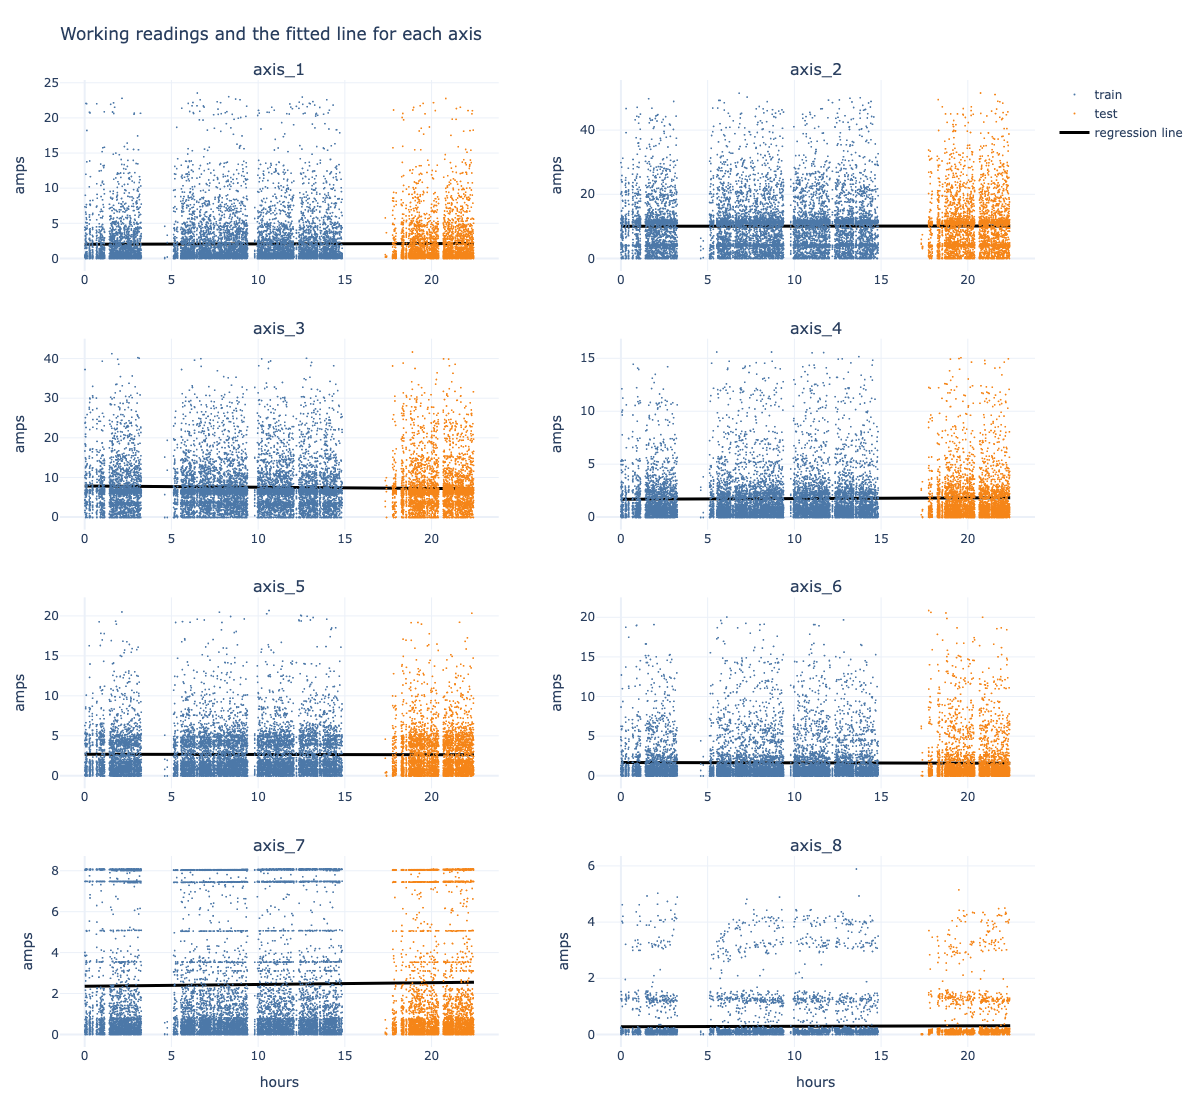

In [6]:
def predict(seconds):
    """Expected current for every axis at the given seconds since T0."""
    seconds = np.asarray(seconds, dtype=float)
    return pd.DataFrame({
        ax: models[ax].intercept_ + models[ax].coef_[0] * seconds for ax in AXES
    })


pred = predict(hist["sec"])
resid = hist[AXES] - pred          # positive = drawing more than expected

fig = make_subplots(rows=4, cols=2, subplot_titles=AXES, vertical_spacing=0.07)
hours_all = np.array([0, hist["sec"].iloc[-1]]) / 3600
for i, ax in enumerate(AXES):
    r, c = i // 2 + 1, i % 2 + 1
    fig.add_trace(go.Scattergl(x=train_work["sec"] / 3600, y=train_work[ax], mode="markers",
                               marker=dict(size=2, color="#4c78a8"), name="train",
                               showlegend=(i == 0)), row=r, col=c)
    fig.add_trace(go.Scattergl(x=test_work["sec"] / 3600, y=test_work[ax], mode="markers",
                               marker=dict(size=2, color="#f58518"), name="test",
                               showlegend=(i == 0)), row=r, col=c)
    fig.add_trace(go.Scatter(x=hours_all, y=predict(hours_all * 3600)[ax], mode="lines",
                             line=dict(color="black", width=3), name="regression line",
                             showlegend=(i == 0)), row=r, col=c)
fig.update_xaxes(title_text="hours", row=4)
fig.update_yaxes(title_text="amps")
fig.update_layout(title="Working readings and the fitted line for each axis")
show(fig, "regression_lines", height=1100)

## 4. Residuals

Residual = real current − predicted current. The width of the residual cloud (its standard
deviation, **σ**) is a natural yardstick, because every axis has a different size. For example
axis 2 swings by several amps and axis 8 by less than one.

In [7]:
sigma = resid.loc[train_work.index].std()
w = resid.loc[train_work.index]

residual_summary = pd.DataFrame({
    "sigma_A": sigma,
    "skew": w.skew(),
    "pct_above_2sigma": (w > 2 * sigma).mean() * 100,
    "pct_above_3sigma": (w > 3 * sigma).mean() * 100,
    "max_residual_A": w.max(),
})
residual_summary.to_csv(OUT_DIR / "residual_summary.csv")
residual_summary

,sigma_A,skew,pct_above_2sigma,pct_above_3sigma,max_residual_A
axis_1,3.300,3.049,5.135,2.634,21.567
axis_2,8.131,1.684,4.809,2.222,41.613
axis_3,5.997,1.898,6.064,2.376,33.644
axis_4,2.242,2.821,5.163,2.778,13.952
axis_5,2.791,2.172,4.454,1.973,18.088
axis_6,2.671,3.132,5.317,2.960,18.448
axis_7,3.052,1.069,0.000,0.000,5.749
axis_8,0.673,4.299,3.372,3.228,5.611


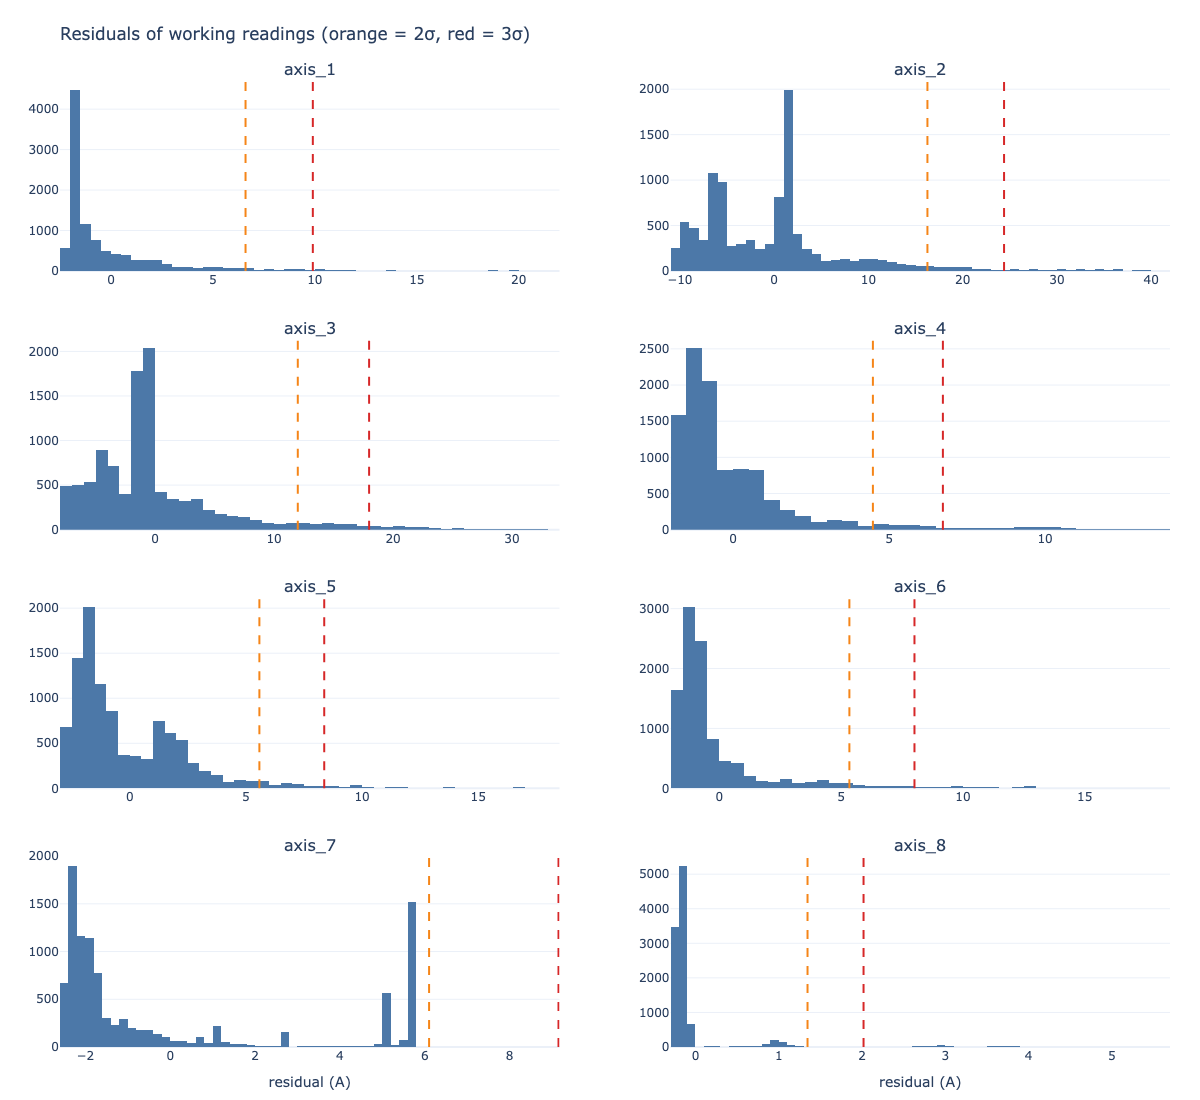

In [8]:
fig = make_subplots(rows=4, cols=2, subplot_titles=AXES, vertical_spacing=0.07)
for i, ax in enumerate(AXES):
    r, c = i // 2 + 1, i % 2 + 1
    fig.add_trace(go.Histogram(x=w[ax], nbinsx=60, marker_color="#4c78a8", showlegend=False),
                  row=r, col=c)
    for k, colour in [(2, "#f58518"), (3, "#d62728")]:
        fig.add_vline(x=k * sigma[ax], line_dash="dash", line_color=colour, row=r, col=c)
fig.update_xaxes(title_text="residual (A)", row=4)
fig.update_layout(title="Residuals of working readings (orange = 2σ, red = 3σ)")
show(fig, "residual_histograms", height=1100)

Every histogram leans to the right. The robot works in cycles, so there are short bursts of
high current even when everything is fine. This tells me that **size alone is a bad alarm
signal**: 2σ is crossed by roughly 5% of the working readings of an axis in a healthy day. Duration has to be part
of the rule.

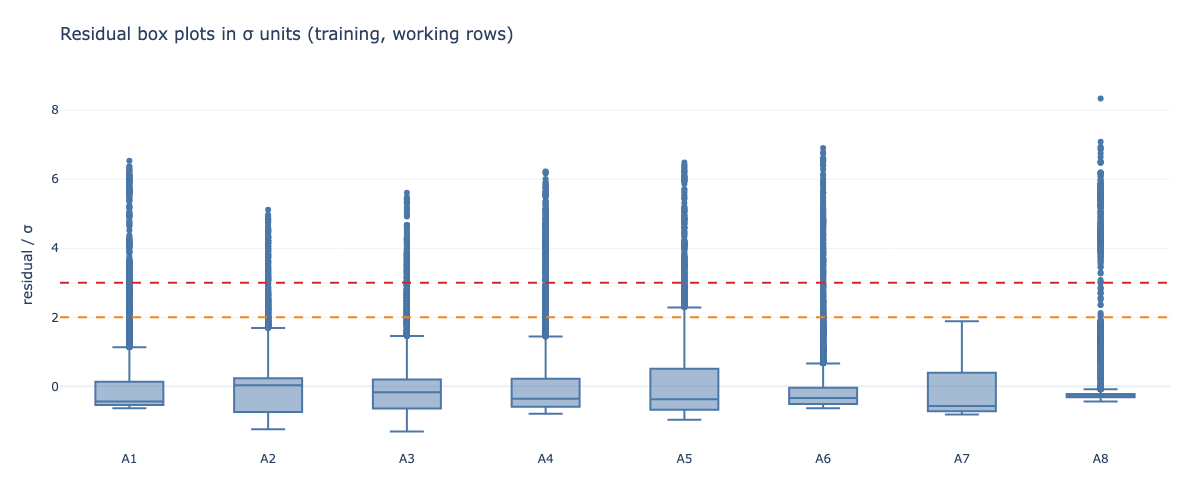

In [9]:
# Same residuals in units of sigma so all axes fit on one scale.
z = (resid / sigma)
fig = go.Figure()
for ax in AXES:
    fig.add_trace(go.Box(y=z.loc[train_work.index, ax], name=ax.replace("axis_", "A"),
                         marker_color="#4c78a8", legendgroup="train", showlegend=False))
fig.add_hline(y=2, line_dash="dash", line_color="#f58518")
fig.add_hline(y=3, line_dash="dash", line_color="#d62728")
fig.update_layout(title="Residual box plots in σ units (training, working rows)",
                  yaxis_title="residual / σ")
show(fig, "residual_boxplots", height=500)

The box plots show the same thing: most points sit close to the line and the outliers are
all on the high side. Axis 7 behaves differently: it never goes above about 8.1 A, so it has no
points beyond 2σ. Next I want to know if the residuals drift over the day, which would mean a trend the
lines didn't capture.

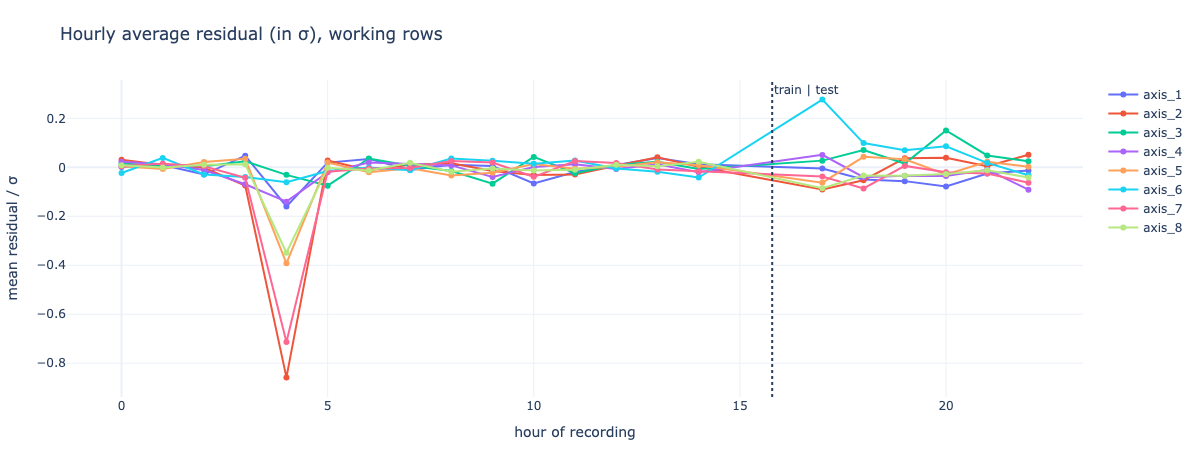

largest hourly average residual: 0.86 sigma


In [10]:
work_all = hist[~hist["idle"]]
hourly = resid.loc[work_all.index].groupby((work_all["sec"] // 3600).astype(int)).mean()

fig = go.Figure()
for ax in AXES:
    fig.add_trace(go.Scatter(x=hourly.index, y=hourly[ax] / sigma[ax], mode="lines+markers", name=ax))
fig.add_vline(x=hist["sec"].iloc[cut] / 3600, line_dash="dot", annotation_text="train | test")
fig.update_layout(title="Hourly average residual (in σ), working rows",
                  xaxis_title="hour of recording", yaxis_title="mean residual / σ")
show(fig, "hourly_residuals", height=450)
print(f"largest hourly average residual: {(hourly / sigma).abs().max().max():.2f} sigma")

Apart from hour 4 (the robot was barely working then, so there are only a few readings),
the hourly averages stay within about ±0.2σ of 0 and do not creep up in the test part. So there
is no hidden drift in this data, which means a sustained rise later on is worth looking at.
(The empty stretches in the plot are recording stops in the data.)

## 5. Finding MinC, MaxC and T

I express the two current thresholds as multiples of each axis' own σ:

- **MinC** (Alert level) = k_alert × σ
- **MaxC** (Error level) = k_error × σ
- **T** = how many seconds the residual must stay above the threshold, without a break

A "run" is a streak of consecutive readings at or above a threshold. If the time between two
readings is more than 3× the usual step, I treat it as a recording gap and the run restarts,
because a hole in the data is not proof that the joint was overloaded the whole time.

Since this whole file is healthy history, the question is: **which (k, T) combinations never
fire on healthy data?**

In [11]:
def find_runs(resid_values, seconds, threshold, max_gap):
    """All runs of consecutive readings with residual >= threshold."""
    hot = np.flatnonzero(resid_values >= threshold)
    cols = ["first", "last", "start_s", "end_s", "duration_s", "readings", "peak"]
    if hot.size == 0:
        return pd.DataFrame(columns=cols)
    new_run = np.r_[True, (np.diff(hot) > 1) | (np.diff(seconds[hot]) > max_gap)]
    starts = np.flatnonzero(new_run)
    ends = np.r_[starts[1:] - 1, hot.size - 1]
    first, last = hot[starts], hot[ends]
    return pd.DataFrame({
        "first": first, "last": last,
        "start_s": seconds[first], "end_s": seconds[last],
        "duration_s": seconds[last] - seconds[first],
        "readings": last - first + 1,
        "peak": np.maximum.reduceat(resid_values[hot], starts),
    })


K_GRID = [1, 1.5, 2, 2.5, 3, 4]
T_GRID = [2, 4, 6, 10, 20, 30]
secs = hist["sec"].to_numpy()

longest = pd.DataFrame(index=K_GRID, columns=AXES, dtype=float)
count_rows = {}
for k in K_GRID:
    per_axis = {ax: find_runs(resid[ax].to_numpy(), secs, k * sigma[ax], MAX_GAP) for ax in AXES}
    for ax in AXES:
        longest.loc[k, ax] = per_axis[ax]["duration_s"].max() if len(per_axis[ax]) else 0
    count_rows[k] = [sum((per_axis[ax]["duration_s"] >= T).sum() for ax in AXES) for T in T_GRID]

sweep = pd.DataFrame(count_rows, index=[f"T={t}s" for t in T_GRID]).T
sweep.index.name = "k (x sigma)"
sweep.to_csv(OUT_DIR / "threshold_sweep.csv")

print("Number of runs on healthy data (all 8 axes, 22.5 hours):")
display(sweep)
print("Longest healthy run, in seconds:")
display(longest)

Number of runs on healthy data (all 8 axes, 22.5 hours):


,T=2s,T=4s,T=6s,T=10s,T=20s,T=30s
k (x sigma),,,,,,
1.000,232,62,3,1,0,0
1.500,113,48,2,1,0,0
2.000,14,2,0,0,0,0
2.500,1,1,0,0,0,0
3.000,0,0,0,0,0,0
4.000,0,0,0,0,0,0


Longest healthy run, in seconds:


,axis_1,axis_2,axis_3,axis_4,axis_5,axis_6,axis_7,axis_8
1.000,5.636,3.915,3.938,3.887,5.627,5.616,11.368,2.140
1.500,5.547,3.849,3.913,2.156,2.098,5.616,11.368,2.140
2.000,2.043,2.000,3.913,0.000,2.015,5.592,0.000,0.000
2.500,0.000,1.955,1.999,0.000,1.992,5.483,0.000,0.000
3.000,0.000,0.000,1.954,0.000,1.976,1.984,0.000,0.000
4.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


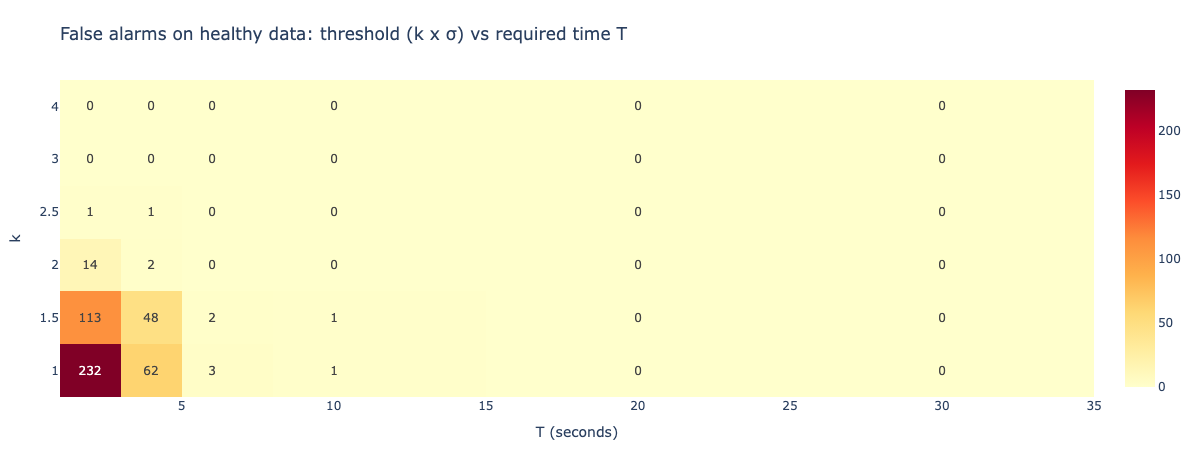

In [12]:
fig = go.Figure(go.Heatmap(z=sweep.to_numpy(), x=T_GRID, y=[str(k) for k in K_GRID],
                           colorscale="YlOrRd", text=sweep.to_numpy(), texttemplate="%{text}"))
fig.update_layout(title="False alarms on healthy data: threshold (k x σ) vs required time T",
                  xaxis_title="T (seconds)", yaxis_title="k")
show(fig, "threshold_sweep", height=450)

What I read from this:

- At 1σ and 1.5σ the robot is above the line for 4 to 6 seconds on several axes, and axis 7
  even reaches 11 s, so those levels would give false alarms.
- At **2σ** the longest healthy streak is only about **5.6 s**. If T is bigger than that,
  healthy data gives zero alarms.
- At **3σ** the longest healthy streak is about **2 s**, which is one or two readings. Reaching
  that level and *staying* there is very unusual for this robot.

So I pick **k_alert = 2, k_error = 3, T = 10 s**. T = 10 s is about six readings in a row,
clearly longer than any healthy streak (5.6 s) but still quick enough to be useful. Using 3σ
for the Error keeps it clearly above the Alert level.

In [13]:
K_ALERT, K_ERROR, T_SEC = 2, 3, 10

thresholds = pd.DataFrame({
    "sigma_A": sigma,
    "MinC_A": K_ALERT * sigma,
    "MaxC_A": K_ERROR * sigma,
    "T_s": T_SEC,
})
thresholds.to_csv(OUT_DIR / "selected_thresholds.csv")
display(thresholds)

# Sanity check on the real history: the chosen rules should stay quiet.
false_alarms = 0
for ax in AXES:
    for name, thr in [("MinC", thresholds.loc[ax, "MinC_A"]), ("MaxC", thresholds.loc[ax, "MaxC_A"])]:
        r = find_runs(resid[ax].to_numpy(), secs, thr, MAX_GAP)
        false_alarms += int((r["duration_s"] >= T_SEC).sum())
print("Alerts/Errors the chosen rules raise on the 22.5 h of healthy history:", false_alarms)
assert false_alarms == 0

,sigma_A,MinC_A,MaxC_A,T_s
axis_1,3.300,6.601,9.901,10
axis_2,8.131,16.262,24.392,10
axis_3,5.997,11.994,17.991,10
axis_4,2.242,4.483,6.725,10
axis_5,2.791,5.582,8.373,10
axis_6,2.671,5.342,8.013,10
axis_7,3.052,6.103,9.155,10
axis_8,0.673,1.346,2.019,10


Alerts/Errors the chosen rules raise on the 22.5 h of healthy history: 0


**In maintenance terms:** a joint that is binding, or a worn part, keeps drawing extra current.
That is the sustained deviation T looks for. I would treat an **Alert** as "check at the next
planned stop" and an **Error** as "stop and inspect". The rules are not tuned on real faults
(there are no labels in this data), they are tuned so a healthy day stays quiet.

## 6. Making the test data

I need test data that looks like the training data but is new. Instead of copying rows, I
generate it from the training statistics:

1. For each axis I take the training mean, standard deviation, min and max of the working rows.
2. I draw **standardized** values (mean 0, SD 1) from a skewed Gamma shape, which matches how the
   real currents lean to the right and can't go below 0.
3. I turn them back into amps with the training mean and SD (z-score reversed).
4. The robot is idle (all zeros) in blocks, with the same share of idle time as the training data.
5. Then I plant a few faults with known right answers.

In [14]:
stats = pd.DataFrame({
    "mean": train_work[AXES].mean(),
    "std": train_work[AXES].std(),
    "min": train_work[AXES].min(),
    "max": train_work[AXES].max(),
})
idle_share = train["idle"].mean()

N = 3000
t_start = hist["reading_time"].iloc[-1] + pd.Timedelta(hours=1)
times = (t_start + pd.to_timedelta(np.cumsum(rng.normal(TYPICAL_STEP, 0.03, N)), unit="s")).round("ms")

# idle / working blocks
idle_flag = np.zeros(N, dtype=bool)
pos, idle_now = 0, True
while pos < N:
    length = rng.integers(30, 111) if idle_now else rng.integers(20, 61)
    idle_flag[pos:pos + length] = idle_now
    pos += length
    idle_now = not idle_now

background = pd.DataFrame({"reading_time": times})
for ax in AXES:
    shape = (stats.loc[ax, "mean"] / stats.loc[ax, "std"]) ** 2
    z_draw = (rng.gamma(shape, 1.0, N) - shape) / np.sqrt(shape)       # mean 0, sd 1
    amps = stats.loc[ax, "mean"] + z_draw * stats.loc[ax, "std"]       # back to amps
    # keep inside the range seen in training (a Gamma tail can overshoot the real maximum)
    background[ax] = np.clip(amps, stats.loc[ax, "min"], stats.loc[ax, "max"])
background.loc[idle_flag, AXES] = 0.0
background["idle"] = (background[AXES] == 0).all(axis=1)

print(f"idle share  train: {idle_share:.1%}   synthetic: {background['idle'].mean():.1%}")

idle share  train: 62.4%   synthetic: 63.7%


### Does it look like the training data?

I scale the working rows of the synthetic data **with the training numbers** (never with their
own): min-max uses the training min and max, and the z-score uses the training mean and SD.
If the generator did its job, the z-scores should have mean ≈ 0 and SD ≈ 1, and the share of
points within 1, 2 and 3 SD should be close to the training shares.

In [15]:
syn_work = background[~background["idle"]]

minmax = (syn_work[AXES] - stats["min"]) / (stats["max"] - stats["min"])
zs = (syn_work[AXES] - stats["mean"]) / stats["std"]
zs_train = (train_work[AXES] - stats["mean"]) / stats["std"]

check = pd.DataFrame({
    "train_mean_A": stats["mean"],
    "synth_mean_A": syn_work[AXES].mean(),
    "train_std_A": stats["std"],
    "synth_std_A": syn_work[AXES].std(),
    "synth_minmax_max": minmax.max(),
    "synth_z_mean": zs.mean(),
    "synth_z_std": zs.std(),
})
for n in (1, 2, 3):
    check[f"train_within_{n}SD_%"] = (zs_train.abs() <= n).mean() * 100
    check[f"synth_within_{n}SD_%"] = (zs.abs() <= n).mean() * 100
check.to_csv(OUT_DIR / "synthetic_vs_training_check.csv")
check.T

,axis_1,axis_2,axis_3,axis_4,axis_5,axis_6,axis_7,axis_8
train_mean_A,2.051,10.056,7.585,1.732,2.670,1.649,2.430,0.286
synth_mean_A,2.165,10.282,7.895,1.833,2.708,1.729,2.237,0.274
train_std_A,3.300,8.131,5.999,2.242,2.791,2.671,3.052,0.673
synth_std_A,3.332,7.916,5.945,2.411,2.767,2.775,2.360,0.661
synth_minmax_max,1.000,0.961,1.000,1.000,0.860,1.000,1.000,1.000
synth_z_mean,0.035,0.028,0.052,0.045,0.014,0.030,-0.063,-0.018
synth_z_std,1.010,0.974,0.991,1.075,0.991,1.039,0.773,0.982
train_within_1SD_%,89.587,75.946,78.235,90.181,88.821,89.099,78.063,91.235
synth_within_1SD_%,88.165,75.688,75.872,86.147,86.330,87.798,87.248,91.560
train_within_2SD_%,94.904,95.201,93.946,94.827,95.536,94.683,100.000,96.628


The means and SDs match well and the z-scores are close to mean 0 / SD 1 for most axes. I clip
the values to the training min and max, so the min-max values stay between 0 and 1. The one weak
spot is axis 7: it is capped at 8.1 A in the real data, so the clipping squeezes its spread a
bit (z SD about 0.77). The within-1/2/3-SD shares are similar but not identical, because a Gamma
is only an approximation of the real distribution. That is good enough for a test stream.

### Planting faults

Each fault sets one axis to `prediction + level × σ` for a number of readings, so I know exactly
what the rules should do (MinC = 2σ, MaxC = 3σ, T = 10 s):

| Fault | Axis | What I plant | Expected |
|---|---|---|---|
| short spike | 2 | 4σ for 3 readings (4 s) | nothing, too short |
| mild overload | 4 | 2.5σ for 12 readings | Alert only |
| strong overload | 6 | 4σ for 20 readings | Alert and Error |
| slow climb | 3 | 1σ → 4σ over 40 readings, then holds | Alert, then Error |
| interrupted | 1 | 4σ ×4, one normal reading, 4σ ×4 | nothing, timer restarts |
| recording gap | 8 | 4σ ×4, 5 readings missing, 4σ ×4 | nothing, timer restarts |

In [16]:
synth = background.copy()
synth["sec"] = (synth["reading_time"] - T0).dt.total_seconds()


def plant(ax, first_row, levels):
    """Set rows to prediction + level*sigma (level 0 = exactly on the line)."""
    for offset, level in enumerate(levels):
        row = first_row + offset
        base = models[ax].intercept_ + models[ax].coef_[0] * synth.at[row, "sec"]
        synth.at[row, ax] = base + level * sigma[ax]


plan = [
    # name,              axis,     row,  levels,                                          expected
    ("short spike",      "axis_2", 300,  [4] * 3,                                         ""),
    ("mild overload",    "axis_4", 700,  [2.5] * 12,                                      "Alert"),
    ("strong overload",  "axis_6", 1200, [4] * 20,                                        "Alert+Error"),
    ("slow climb",       "axis_3", 1700, list(np.linspace(1, 4, 40)) + [4] * 10,          "Alert+Error"),
    ("interrupted",      "axis_1", 2200, [4] * 4 + [0] + [4] * 4,                         ""),
    ("recording gap",    "axis_8", 2600, [4] * 4 + [4] * 5 + [4] * 4,                     ""),
]

fault_rows = []
for name, ax, row, levels, expected in plan:
    plant(ax, row, levels)
    fault_rows.append({"fault": name, "axis": ax, "expected": expected or "nothing",
                       "start_s": synth.at[row, "sec"], "end_s": synth.at[row + len(levels) - 1, "sec"]})

# the recording gap: remove the 5 middle readings (rows 2604-2608)
synth = synth.drop(index=range(2604, 2609)).reset_index(drop=True)
faults = pd.DataFrame(fault_rows)
display(faults)

# Save in the same layout as the original CSV so the simulator can read it.
out_csv = pd.DataFrame({"Trait": "current"}, index=synth.index)
for i, ax in enumerate(AXES, start=1):
    out_csv[f"Axis #{i}"] = synth[ax].round(5)
out_csv["Time"] = synth["reading_time"].dt.strftime("%Y-%m-%d %H:%M:%S.%f") + "+00:00"
out_csv.to_csv(DATA_DIR / "synthetic_test.csv", index=False)
print(len(out_csv), "readings saved to data/synthetic_test.csv")

,fault,axis,expected,start_s,end_s
0,short spike,axis_2,nothing,"84,963.018","84,966.814"
1,mild overload,axis_4,Alert,"85,718.266","85,739.217"
2,strong overload,axis_6,Alert+Error,"86,663.384","86,699.196"
3,slow climb,axis_3,Alert+Error,"87,608.788","87,701.480"
4,interrupted,axis_1,nothing,"88,554.539","88,569.680"
5,recording gap,axis_8,nothing,"89,311.110","89,333.817"


2995 readings saved to data/synthetic_test.csv


## 7. Streaming the test data through Neon

For every batch of 50 readings:

1. the simulator hands me the next readings from the CSV, one at a time,
2. I insert the batch into the `synthetic_test_readings` table in Neon,
3. I **query the rows back from the database** and use those for the prediction,
4. the detector updates its timers reading by reading, and keeps its state between batches.

Alerts and Errors are logged to a CSV and to the `alert_events` table.

In [17]:
CREATE_READINGS = """
CREATE TABLE IF NOT EXISTS synthetic_test_readings (
    run_id TEXT NOT NULL,
    sequence_no INTEGER NOT NULL,
    trait TEXT NOT NULL,
    axis_1 DOUBLE PRECISION NOT NULL, axis_2 DOUBLE PRECISION NOT NULL,
    axis_3 DOUBLE PRECISION NOT NULL, axis_4 DOUBLE PRECISION NOT NULL,
    axis_5 DOUBLE PRECISION NOT NULL, axis_6 DOUBLE PRECISION NOT NULL,
    axis_7 DOUBLE PRECISION NOT NULL, axis_8 DOUBLE PRECISION NOT NULL,
    reading_time TIMESTAMPTZ NOT NULL,
    inserted_at TIMESTAMPTZ NOT NULL DEFAULT clock_timestamp(),
    PRIMARY KEY (run_id, sequence_no),
    UNIQUE (run_id, reading_time)
)
"""

CREATE_EVENTS = """
CREATE TABLE IF NOT EXISTS alert_events (
    run_id TEXT NOT NULL,
    axis TEXT NOT NULL,
    level TEXT NOT NULL CHECK (level IN ('Alert', 'Error')),
    threshold_a DOUBLE PRECISION NOT NULL,
    required_duration_seconds DOUBLE PRECISION NOT NULL,
    start_time TIMESTAMPTZ NOT NULL,
    triggered_at TIMESTAMPTZ NOT NULL,
    last_exceedance TIMESTAMPTZ NOT NULL,
    observed_duration_seconds DOUBLE PRECISION NOT NULL,
    sample_count INTEGER NOT NULL,
    peak_residual_a DOUBLE PRECISION NOT NULL,
    logged_at TIMESTAMPTZ NOT NULL DEFAULT now(),
    PRIMARY KEY (run_id, axis, level, start_time)
)
"""

INSERT_READING = """
INSERT INTO synthetic_test_readings
    (run_id, sequence_no, trait, axis_1, axis_2, axis_3, axis_4,
     axis_5, axis_6, axis_7, axis_8, reading_time)
VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s, %s, %s, %s)
"""

SELECT_NEW = """
SELECT sequence_no, reading_time, axis_1, axis_2, axis_3, axis_4,
       axis_5, axis_6, axis_7, axis_8
FROM synthetic_test_readings
WHERE run_id = %s AND sequence_no > %s
ORDER BY sequence_no
"""

with get_connection() as conn:
    conn.execute(CREATE_READINGS)
    conn.execute(CREATE_EVENTS)
print("tables ready")

tables ready


The detector is one small function. For each axis and each level (Alert / Error) it keeps a
little record: when the current streak started, when it last continued, and the event (if any)
that streak has already produced. A reading extends the streak if it is above the threshold
**and** arrives within the allowed gap; otherwise the streak ends.

In [18]:
def new_tracker():
    return {"start": None, "last": None, "start_ts": None, "last_ts": None,
            "n": 0, "peak": 0.0, "event": None}


def update_tracker(tr, t, ts, residual, threshold, axis, level, events):
    """Feed one reading to one tracker; open or extend an event when T is reached."""
    hot = residual >= threshold
    continues = tr["last"] is not None and (t - tr["last"]) <= MAX_GAP

    if hot and continues:
        tr["last"], tr["last_ts"] = t, ts
        tr["n"] += 1
        tr["peak"] = max(tr["peak"], residual)
    elif hot:                                  # a new streak starts here
        tr.update(start=t, last=t, start_ts=ts, last_ts=ts, n=1, peak=residual, event=None)
    else:                                      # streak is over
        tr.update(start=None, last=None, start_ts=None, last_ts=None, n=0, peak=0.0, event=None)
        return

    if tr["last"] - tr["start"] >= T_SEC:
        if tr["event"] is None:
            tr["event"] = {"axis": axis, "level": level, "threshold_A": threshold,
                           "start_s": tr["start"], "start_time": tr["start_ts"],
                           "triggered_s": t, "triggered_at": ts}
            events.append(tr["event"])
        tr["event"].update(end_s=tr["last"], end_time=tr["last_ts"],
                           duration_s=tr["last"] - tr["start"],
                           readings=tr["n"], peak_residual_A=tr["peak"])


def store_and_fetch(conn, run_id, batch, last_seq):
    """Insert a batch, then query it back from Neon."""
    values = [(run_id, seq, rec["trait"], *[float(rec[ax]) for ax in AXES],
               rec["reading_time"].to_pydatetime()) for seq, rec in batch]
    with conn.cursor() as cur:
        cur.executemany(INSERT_READING, values)
    conn.commit()
    with conn.cursor(row_factory=dict_row) as cur:
        cur.execute(SELECT_NEW, (run_id, last_seq))
        got = pd.DataFrame(cur.fetchall())
    conn.commit()
    assert got["sequence_no"].tolist() == [seq for seq, _ in batch], "database returned the wrong rows"
    got["reading_time"] = pd.to_datetime(got["reading_time"], utc=True)
    return got

In [19]:
RUN_ID = uuid.uuid4().hex[:12]
BATCH_SIZE = 50
PAUSE_S = 0.05            # tiny pause between batches to mimic a live feed

thr_alert = thresholds["MinC_A"]
thr_error = thresholds["MaxC_A"]

trackers = {(ax, lvl): new_tracker() for ax in AXES for lvl in ("Alert", "Error")}
events = []
fetched = []
resid_log = []

sim = StreamingSimulator(DATA_DIR / "synthetic_test.csv", interval=0)
seq = 0
t_begin = time.time()

with get_connection() as conn:
    while True:
        batch = []
        for _ in range(BATCH_SIZE):
            rec = sim.nextDataPoint()
            if rec is None:
                break
            seq += 1
            batch.append((seq, rec))
        if not batch:
            break

        got = store_and_fetch(conn, RUN_ID, batch, batch[0][0] - 1)
        fetched.append(got)

        sec = (got["reading_time"] - T0).dt.total_seconds().to_numpy()
        res = got[AXES].reset_index(drop=True) - predict(sec)
        resid_log.append(res.assign(sec=sec, reading_time=got["reading_time"].to_numpy()))

        for i in range(len(got)):
            ts = got["reading_time"].iloc[i]
            for ax in AXES:
                r = res[ax].iloc[i]
                update_tracker(trackers[(ax, "Alert")], sec[i], ts, r, thr_alert[ax], ax, "Alert", events)
                update_tracker(trackers[(ax, "Error")], sec[i], ts, r, thr_error[ax], ax, "Error", events)
        time.sleep(PAUSE_S)

stream = pd.concat(fetched, ignore_index=True)
stream_resid = pd.concat(resid_log, ignore_index=True)
print(f"run {RUN_ID}: {len(stream)} readings streamed in {time.time() - t_begin:.0f} s, "
      f"{len(events)} events detected")

run f954acd7797d: 2995 readings streamed in 21 s, 5 events detected


Two checks before I trust it: (1) what came back from Neon is the same as the CSV, and (2) the
live detector agrees with a completely separate offline calculation (`find_runs`) on the same
residuals.

In [20]:
# 1. database round trip
csv_back = pd.read_csv(DATA_DIR / "synthetic_test.csv")
assert len(stream) == len(csv_back)
assert np.allclose(stream[AXES].to_numpy(), csv_back[[f"Axis #{i}" for i in range(1, 9)]].to_numpy())
print("rows from Neon match the CSV:", len(stream))

# 2. live events vs offline recalculation
events_df = pd.DataFrame(events)
sr, ssec = stream_resid, stream_resid["sec"].to_numpy()
offline = []
for ax in AXES:
    for lvl, thr in (("Alert", thr_alert[ax]), ("Error", thr_error[ax])):
        runs = find_runs(sr[ax].to_numpy(), ssec, thr, MAX_GAP)
        for _, row in runs[runs["duration_s"] >= T_SEC].iterrows():
            offline.append((ax, lvl, round(row["start_s"], 3), round(row["duration_s"], 3)))

live = sorted((e["axis"], e["level"], round(e["start_s"], 3), round(e["duration_s"], 3)) for e in events)
assert live == sorted(offline), "live and offline results differ"
print("live detector == offline recalculation:", len(live), "events")

rows from Neon match the CSV: 2995
live detector == offline recalculation: 5 events


In [21]:
# Compare with what I planted.
events_df = events_df.sort_values(["start_s", "level"]).reset_index(drop=True)
verdicts = []
for _, f in faults.iterrows():
    hit = events_df[(events_df["axis"] == f["axis"]) &
                    (events_df["start_s"] >= f["start_s"] - 2) &
                    (events_df["start_s"] <= f["end_s"] + 2)]
    found = "+".join(sorted(hit["level"].unique(), key=["Alert", "Error"].index)) or "nothing"
    verdicts.append({**f.to_dict(), "found": found, "correct": found == f["expected"]})

verdicts = pd.DataFrame(verdicts)
verdicts.to_csv(OUT_DIR / "fault_check.csv", index=False)
display(verdicts[["fault", "axis", "expected", "found", "correct"]])

inside = sum(len(events_df[(events_df["axis"] == f["axis"]) &
                           (events_df["start_s"] >= f["start_s"] - 2) &
                           (events_df["start_s"] <= f["end_s"] + 2)]) for _, f in faults.iterrows())
print("events outside the planted faults (false alarms):", len(events_df) - inside)
assert verdicts["correct"].all() and len(events_df) == inside

,fault,axis,expected,found,correct
0,short spike,axis_2,nothing,nothing,True
1,mild overload,axis_4,Alert,Alert,True
2,strong overload,axis_6,Alert+Error,Alert+Error,True
3,slow climb,axis_3,Alert+Error,Alert+Error,True
4,interrupted,axis_1,nothing,nothing,True
5,recording gap,axis_8,nothing,nothing,True


events outside the planted faults (false alarms): 0


### Event log

Every Alert and Error goes to `results/events.csv` and to the `alert_events` table in Neon.

In [22]:
events_out = events_df[["axis", "level", "threshold_A", "start_time", "end_time",
                        "duration_s", "readings", "peak_residual_A"]].copy()
events_out.insert(0, "run_id", RUN_ID)
events_out.to_csv(OUT_DIR / "events.csv", index=False)

INSERT_EVENT = """
INSERT INTO alert_events
    (run_id, axis, level, threshold_a, required_duration_seconds, start_time,
     triggered_at, last_exceedance, observed_duration_seconds, sample_count, peak_residual_a)
VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s, %s, %s)
ON CONFLICT DO NOTHING
"""

rows = [(RUN_ID, e["axis"], e["level"], float(e["threshold_A"]), float(T_SEC),
         e["start_time"].to_pydatetime(), e["triggered_at"].to_pydatetime(),
         e["end_time"].to_pydatetime(), float(e["duration_s"]), int(e["readings"]),
         float(e["peak_residual_A"])) for e in events]

with get_connection() as conn:
    with conn.cursor() as cur:
        cur.executemany(INSERT_EVENT, rows)
    conn.commit()
    with conn.cursor(row_factory=dict_row) as cur:
        cur.execute("""SELECT axis, level, observed_duration_seconds AS duration_s,
                              peak_residual_a, start_time
                       FROM alert_events WHERE run_id = %s ORDER BY start_time, level""", (RUN_ID,))
        stored = pd.DataFrame(cur.fetchall())

assert len(stored) == len(events)
print(f"{len(stored)} events stored in Neon for run {RUN_ID}")
stored

5 events stored in Neon for run f954acd7797d


,axis,level,duration_s,peak_residual_a,start_time
0,axis_4,Alert,20.951,5.604,2022-10-18 12:07:01.926000+00:00
1,axis_6,Alert,35.812,10.684,2022-10-18 12:22:47.044000+00:00
2,axis_6,Error,35.812,10.684,2022-10-18 12:22:47.044000+00:00
3,axis_3,Alert,67.999,23.988,2022-10-18 12:38:57.141000+00:00
4,axis_3,Error,43.430,23.988,2022-10-18 12:39:21.710000+00:00


### Where the alerts happen

Every chart shows the real current (grey), the regression line (black), and the Alert / Error
levels as dashed lines above the line. The coloured bands mark each event and are labelled
with its duration.

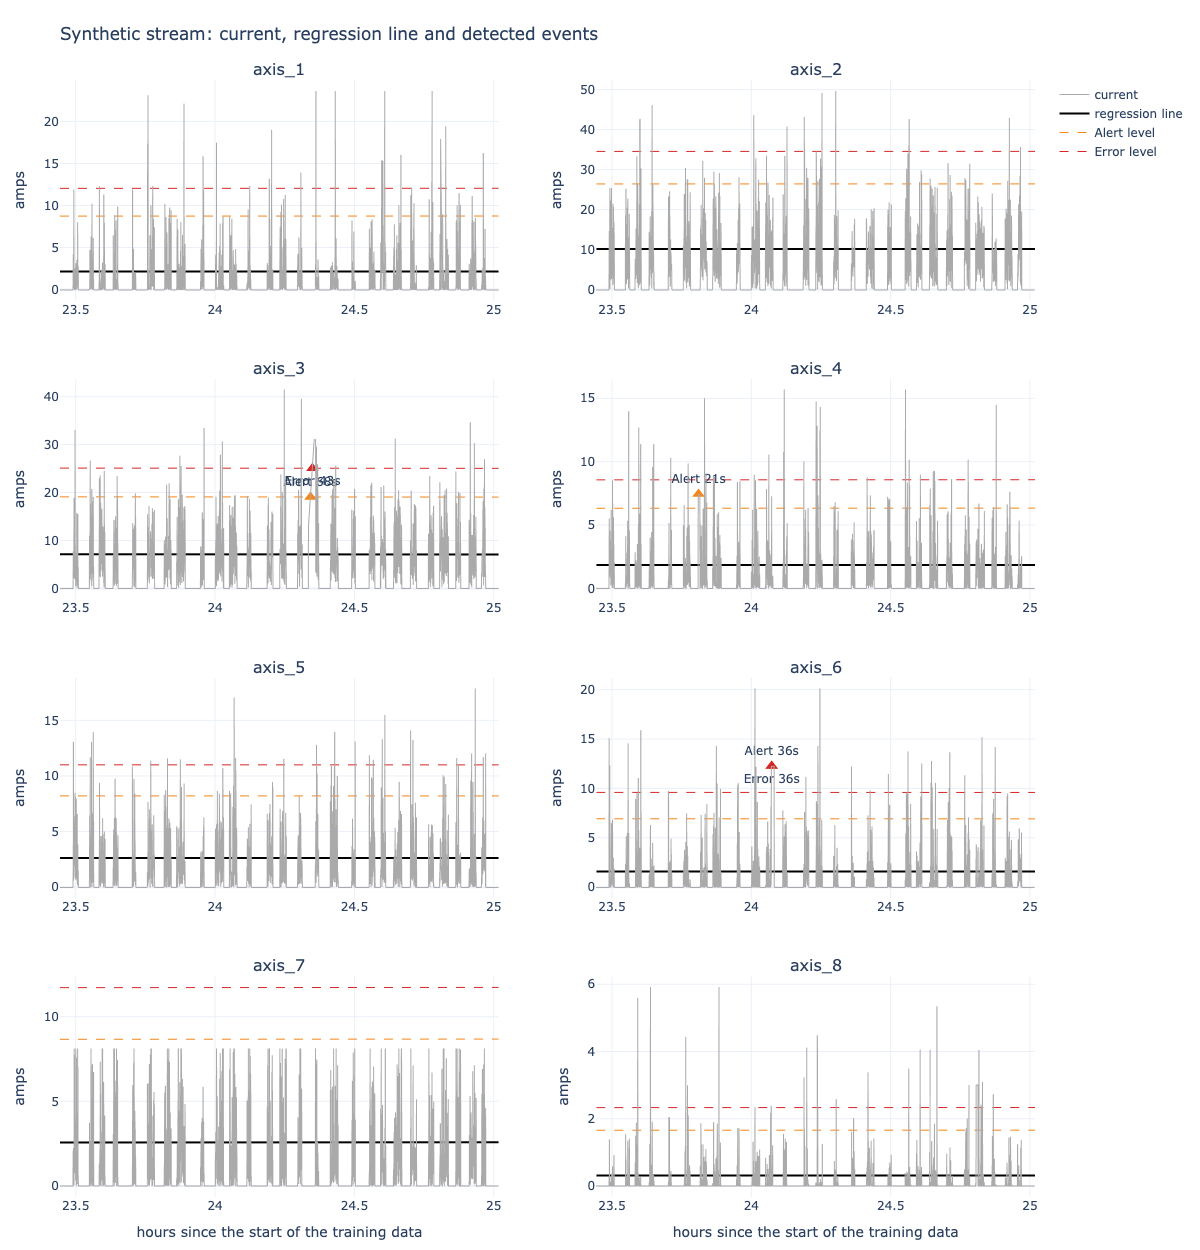

In [23]:
EVENT_COLOUR = {"Alert": "#f58518", "Error": "#d62728"}
hrs_stream = stream_resid["sec"] / 3600
line_t = np.array([stream_resid["sec"].min(), stream_resid["sec"].max()])
line_pred = predict(line_t)

fig = make_subplots(rows=4, cols=2, subplot_titles=AXES, vertical_spacing=0.07)
for i, ax in enumerate(AXES):
    r, c = i // 2 + 1, i % 2 + 1
    fig.add_trace(go.Scattergl(x=hrs_stream, y=stream[ax], mode="lines",
                               line=dict(color="#aaaaaa", width=1), name="current",
                               showlegend=(i == 0)), row=r, col=c)
    fig.add_trace(go.Scatter(x=line_t / 3600, y=line_pred[ax], mode="lines",
                             line=dict(color="black", width=2), name="regression line",
                             showlegend=(i == 0)), row=r, col=c)
    for lvl, thr in (("Alert", thr_alert[ax]), ("Error", thr_error[ax])):
        fig.add_trace(go.Scatter(x=line_t / 3600, y=line_pred[ax] + thr, mode="lines",
                                 line=dict(color=EVENT_COLOUR[lvl], dash="dash", width=1),
                                 name=f"{lvl} level", showlegend=(i == 0)), row=r, col=c)
    for e in events_df[events_df["axis"] == ax].itertuples():
        fig.add_trace(go.Scatter(x=[e.start_s / 3600], y=[stream[ax].iloc[
                                    (stream_resid["sec"] - e.start_s).abs().idxmin()]],
                                 mode="markers+text", text=[f"{e.level} {e.duration_s:.0f}s"],
                                 textposition="top center" if e.level == "Alert" else "bottom center",
                                 marker=dict(size=11, color=EVENT_COLOUR[e.level], symbol="triangle-up"),
                                 showlegend=False), row=r, col=c)
fig.update_xaxes(title_text="hours since the start of the training data", row=4)
fig.update_yaxes(title_text="amps")
fig.update_layout(title="Synthetic stream: current, regression line and detected events")
show(fig, "stream_overview", height=1250)

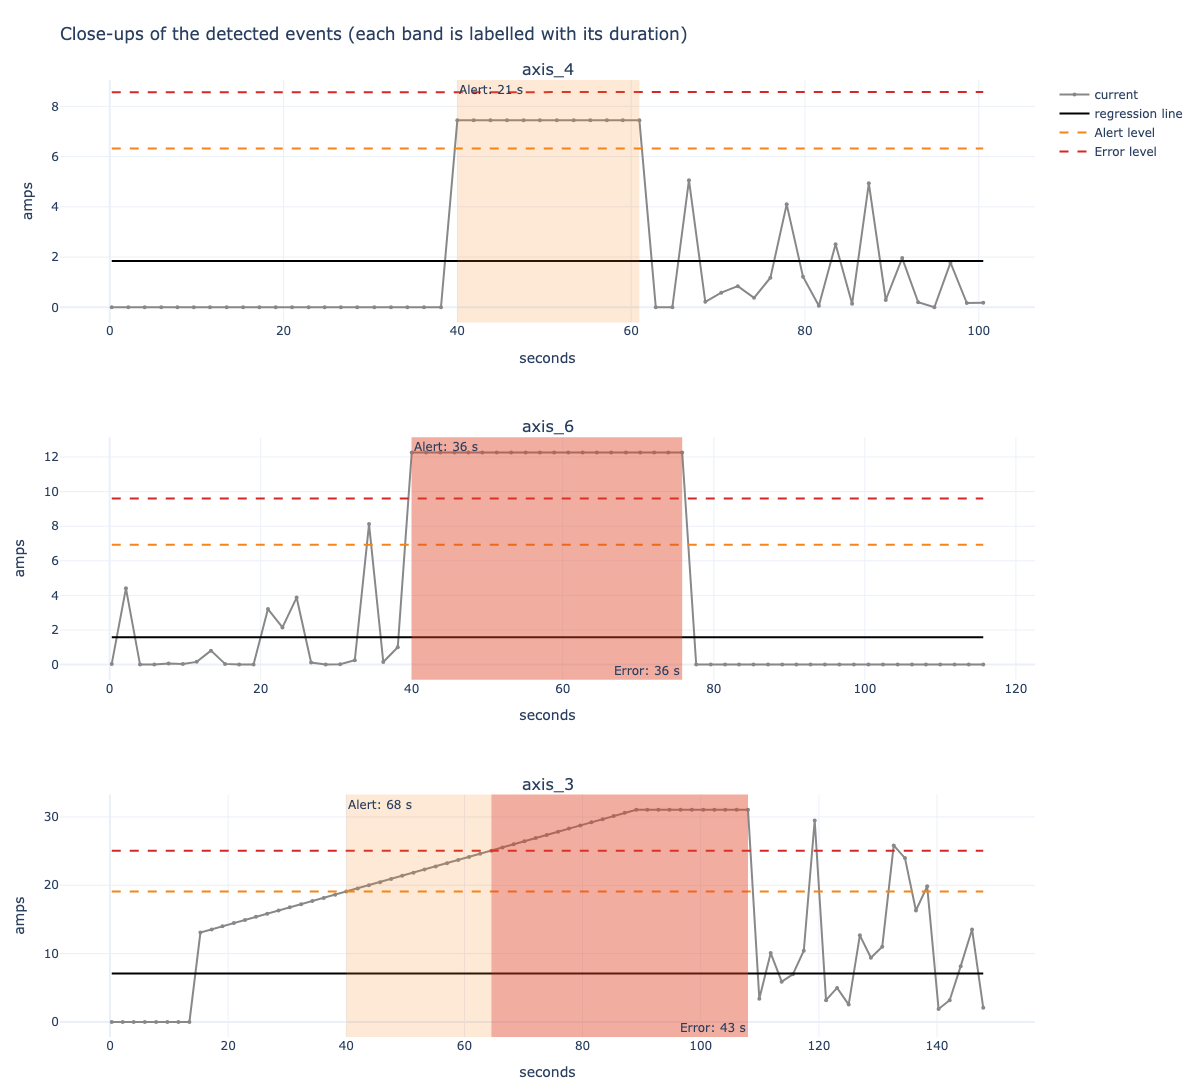

In [24]:
# Close-ups of every axis that raised something.
axes_with_events = list(events_df["axis"].unique())
fig = make_subplots(rows=len(axes_with_events), cols=1, subplot_titles=axes_with_events,
                    vertical_spacing=0.12)
for i, ax in enumerate(axes_with_events, start=1):
    ev = events_df[events_df["axis"] == ax]
    lo, hi = ev["start_s"].min() - 40, ev["end_s"].max() + 40
    m = (stream_resid["sec"] >= lo) & (stream_resid["sec"] <= hi)
    t_win = stream_resid.loc[m, "sec"]
    p = predict(t_win.to_numpy())[ax].to_numpy()
    fig.add_trace(go.Scatter(x=t_win - lo, y=stream.loc[m, ax], mode="lines+markers",
                             line=dict(color="#888888"), marker=dict(size=4),
                             name="current", showlegend=(i == 1)), row=i, col=1)
    fig.add_trace(go.Scatter(x=t_win - lo, y=p, mode="lines", line=dict(color="black"),
                             name="regression line", showlegend=(i == 1)), row=i, col=1)
    for lvl, thr in (("Alert", thr_alert[ax]), ("Error", thr_error[ax])):
        fig.add_trace(go.Scatter(x=t_win - lo, y=p + thr, mode="lines",
                                 line=dict(color=EVENT_COLOUR[lvl], dash="dash"),
                                 name=f"{lvl} level", showlegend=(i == 1)), row=i, col=1)
    for e in ev.itertuples():
        fig.add_vrect(x0=e.start_s - lo, x1=e.end_s - lo, fillcolor=EVENT_COLOUR[e.level],
                      opacity=0.18 if e.level == "Alert" else 0.3, line_width=0, row=i, col=1,
                      annotation_text=f"{e.level}: {e.duration_s:.0f} s",
                      annotation_position="top left" if e.level == "Alert" else "bottom right")
    fig.update_xaxes(title_text="seconds", row=i, col=1)
    fig.update_yaxes(title_text="amps", row=i, col=1)
fig.update_layout(title="Close-ups of the detected events (each band is labelled with its duration)")
show(fig, "event_closeups", height=330 * len(axes_with_events) + 100)

## 8. Conclusions

**Models.** Each axis got a straight line fitted on the working readings of the first 70% of
the day. The slopes are all within ±0.04 A per hour and R² is about 0, on training and test.
For this robot the line is basically the typical working current of each joint, and there is
no trend over the 22.5 hours.

**Residuals.** All eight axes are skewed to the right. About 4 to 6% of working readings sit
above 2σ and about 2 to 3% above 3σ (axis 7 is capped at 8.1 A, so it never gets there). That
is a lot of single high readings in a healthy day, so size alone can't be the alarm.

**Thresholds.** On the whole healthy history, the longest streak above 2σ is about 5.6 s and
above 3σ about 2 s, while a lower level (1σ or 1.5σ) produces a streak of 11 s. So I chose:

| Setting | Value | Why |
|---|---|---|
| MinC (Alert) | 2 × σ of each axis | lowest level where healthy streaks stay under 6 s |
| MaxC (Error) | 3 × σ of each axis | healthy streaks are 1 to 2 readings, clearly worse than an Alert |
| T | 10 s | longer than every healthy streak at 2σ (5.6 s), but only about six readings |

With these values the rules raise **0 events** on the 22.5 hours of real data
(`results/threshold_sweep.csv` and the heatmap show the full picture).

**Streaming test.** The 2,995 synthetic readings went through Neon in batches of 50 and were
read back. All six planted faults got the expected answer (short spike, interrupted run and
recording gap gave nothing; the mild overload gave an Alert; the strong overload and the slow
climb gave an Alert and an Error), with no false alarms elsewhere. The live detector and the
separate offline calculation agree exactly, and the 5 events are in `results/events.csv` and in
the `alert_events` table.

**Predictive maintenance view.** An Alert would be "look at it at the next planned stop" and
an Error "stop and inspect". Because the rules stay silent on a normal day, a maintenance team
has a reason to trust them when they do fire.

**Limits.**
- There are no confirmed faults in the data, so I can't measure how many real failures this
  catches. The thresholds are set to keep a healthy day quiet.
- The test data is made from per-axis statistics, so it does not keep the way joints move
  together, and the planted faults are very clean (flat plateaus). Real wear would be messier.
- The data has two long recording stops (around hours 3.5–5 and 15–17.5). I treat gaps as breaks
  in a streak.
- σ comes from one day. With weeks of data the lines and σ should be refitted, and a slope that
  starts climbing would be the early warning of wear.